## Background to crime mapping

Queensland is generally a safe place to live, but crimes do occur. The police are responsible for preventing crime and apprehending offenders. To support this effort, it is important to understand the behavior and motivations of criminals. One way to do this is by mapping crime incidents. These maps can be linked to other geographical information, such as where criminal activity originates (home, transit points, gathering places) and locations where crimes are likely to occur (shops, tourist spots, etc.).  

The police collect data on crime, including the location (by ABS mesh block), time, and type of each crime. When this data is mapped alongside other geographical information, it can reveal patterns that are related to population demographics and land use (Crime mapping - Wikipedia, 2024).

This notebook provides code for mapping crime incidents and other data to examine crime patterns from a geographical perspective. The goal is to interpret these spatial patterns using theories from environmental criminology (Crime mapping - Wikipedia, 2024), focusing on identifying patterns and offering explanations. 

While mapping police data by ABS mesh blocks is enough to highlight crime hotspots, you are encouraged to conduct further research and analysis to explore the geographic factors influencing these hotspots. Some suggestions include (Chainey and Ratcliffe, 2005):
-	Identifying spatial and temporal crime patterns that align with criminals' decision-making (i.e. achieving their goals while avoiding capture).
-	Analyzing crime in relation to socio-economic factors, such as disadvantaged areas.
-	Examining local trends, such as crime rates as a percentage of regional characteristics (e.g. unemployment or other demographics).
-	Investigating the relationship between the distance from crime opportunities (e.g., shops) and the occurrence of crimes (distance decay).



Crime mapping - Wikipedia, 2024, [en.wikipedia.org/wiki/Crime_mapping](https://en.wikipedia.org/wiki/Crime_mapping)

Chainey S. and Ratcliffe J. (2005) GIS and Crime Mapping. John Wiley & Sons. [UQ Library](https://search.library.uq.edu.au/permalink/f/18av8c1/61UQ_ALMA21105403180003131)

The tasks illustrated in the notebook to map crime incidences and background population and land use data are:

1 [Get crime data for suburb West End](#1-Get-crime-data-for-suburb-West-End)

2 [Hotspot map of crime assaults for 2023](#2-Hotspot-map-of-crime-assaults-for-2023)

Note: A further notebook will be provided to access ABS data directly from ArcGIS Online, including an additional layer for socio-economic disadvantage.

---

#### 1 Get crime data for interested suburb in 2025

Crime data for last 5 years is available from [Queensland Police Services](https://www.data.qld.gov.au/dataset/crime-locations-2000-present) (QPS) through a custom web service (see QGOV CrimeMapAPI.docx). Data may be viewed with an [interactive webmap](https://qps-ocm.s3-ap-southeast-2.amazonaws.com/index.html). The QPS API supports getting relevant geographical data (i.e. police stations, police-related boundaries, suburbs and local government area) and offence data by [ABS meshblocks](https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs-edition-3/jul2021-jun2026). 

As an example of using the QPS API I get suburb boundaries and offences for the past year and for the interested suburb picked by user. The suburb boundary is returned as a FeatureCollection in [GeoJSON](FeatureCollection) format. This can directly be made into a [GeoPandas](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.from_features.html) geodataframe. The offences are returned as a dictionary which can directly be made into a Pandas dataframe.

In [1]:
# Uncomment to install geopandas
# !pip install geopandas

In [2]:
# parameter settings
# Query string parameters
locationType = "SUBURB"
locationName = "Logan Central"
format = "JSON"
startDate = "01-01-2024"
endDate =   "12-31-2025"


In [3]:
# Connect to QPS REST API for location? using Python requests library
import requests
import json
import geopandas

# Set the URL for the REST API for locations
loc_url = "https://a5c7zwf7e5.execute-api.ap-southeast-2.amazonaws.com/dev/locations?"


# Build the URL for the REST API
loc_query = loc_url + "locationType=" + locationType + "&locationName=" + locationName + "&format=" + format

# Send the request to the REST API  
response = requests.get(loc_query)

# Check if the request was successful
if response.status_code == 200:
    # Convert the response to JSON
    data = response.json()
    # print(json.dumps(response.json()))   # print JSON response
    # Convert json to a dataframe
    sub_df = geopandas.GeoDataFrame.from_features(data[0],crs="EPSG:4326")
else:
    print('Get location request failed')

In [4]:
# Print the dataframe, it's just the suburb feature
sub_df

,geometry,Name,Type
0,"POLYGON ((153.105 -27.63571, 153.10261 -27.634...",Logan Central,Suburb


In [5]:
# Connect to QPS REST API for offences? using Python requests library
import requests, json
import pandas

# Set the URL for the REST API for offences
off_url = "https://a5c7zwf7e5.execute-api.ap-southeast-2.amazonaws.com/dev/offences?"

# Build the URL for the REST API
off_query = off_url + "locationType="+locationType + "&locationName="+locationName + \
            "&startDate="+startDate + "&endDate="+endDate + "&format="+format 

# Send the request to the REST API  
response = requests.get(off_query)

# Check if the request was successful
if response.status_code == 200:
    # Convert the response to JSON
    data = response.json()
    off_df = pandas.json_normalize(data)
else:
    print('Get location request failed')

In [6]:
off_df

,Type,Date,Postcode,Area of Interest,ABS Meshblock
0,Unlawful Entry,2024-01-01 00:00:00,4114,Logan Central,30563656400
1,Drug Offences,2024-01-01 08:00:00,4114,Logan Central,30395140000
2,Other Theft (excl. Unlawful Entry),2024-01-01 13:45:00,4114,Logan Central,30397415000
3,Trespassing and Vagrancy,2024-01-01 14:35:00,4114,Logan Central,30395340000
4,Other Theft (excl. Unlawful Entry),2024-01-01 15:20:00,4114,Logan Central,30395350000
...,...,...,...,...,...
4480,Assault,2025-12-30 21:30:29,4114,Logan Central,30397412000
4481,Other Theft (excl. Unlawful Entry),2025-12-30 21:30:29,4114,Logan Central,30397412000
4482,Fraud,2025-12-31 00:01:00,4114,Logan Central,30397280000
4483,Trespassing and Vagrancy,2025-12-31 00:09:59,4114,Logan Central,30396440000


#### List All distinct crime types

In [7]:
# Distinct crime types of the selected area
off_df['Type'].unique().tolist()

['Unlawful Entry',
 'Drug Offences',
 'Other Theft (excl. Unlawful Entry)',
 'Trespassing and Vagrancy',
 'Good Order Offences',
 'Unlawful Use of Motor Vehicle',
 'Assault',
 'Other Property Damage',
 'Robbery',
 'Fraud',
 'Weapons Act Offences',
 'Traffic and Related Offences',
 'Handling Stolen Goods',
 'Other Offences Against the Person',
 'Miscellaneous Offences',
 'Arson',
 'Liquor (excl. Drunkenness)']

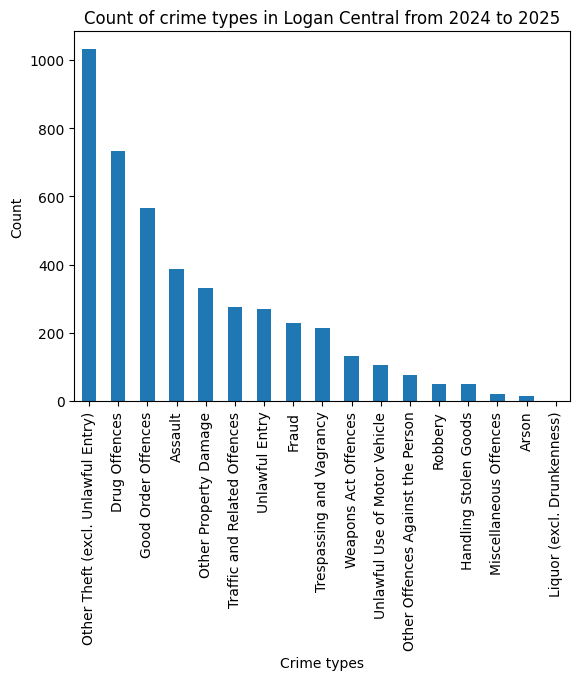

In [8]:
import matplotlib.pyplot as plt

off_df['Type'].value_counts().plot(kind='bar')

plt.xlabel('Crime types')
plt.ylabel('Count')
plt.title(f'Count of crime types in {locationName} from 2024 to 2025')
plt.show()

#### 2 Mapping to highlight (similar to hotspot) target crime 

The crime data has attributes for the offence type and ABS Meshblock codes. Only selected offences will be considered. Meshblock data is read with a spatial filter to get rows overlapping selected suburb boundary.

#### Mesh Block recording Landuse types

In [9]:
# Spatial filter by selected suburb

sub_df.to_crs(epsg=7844, inplace=True) # convert to GDA2020
path_mb = "https://shire.science.uq.edu.au/Geospatial/GEOM3005_7004/data/abs21_mb.zip"
gdf_mb = geopandas.read_file(path_mb, mask=sub_df) 
print(f"Number of census mesh blocks for {locationName} is {len(gdf_mb)}")

Number of census mesh blocks for Logan Central is 105


In [10]:
gdf_mb.columns

Index(['MB_CODE21', 'MB_CAT21', 'SA1_CODE21', 'SA2_CODE21', 'SA2_NAME21',
       'SA3_CODE21', 'SA3_NAME21', 'SA4_CODE21', 'SA4_NAME21', 'GCC_CODE21',
       'GCC_NAME21', 'AREASQKM21', 'Shape_Leng', 'Shape_Area', 'Dwelling',
       'Person', 'geometry'],
      dtype='str')

In [11]:
# Distinct crime types of the selected area
gdf_mb['MB_CAT21'].unique().tolist()

['Other', 'Residential', 'Parkland', 'Commercial', 'Transport', 'Education']

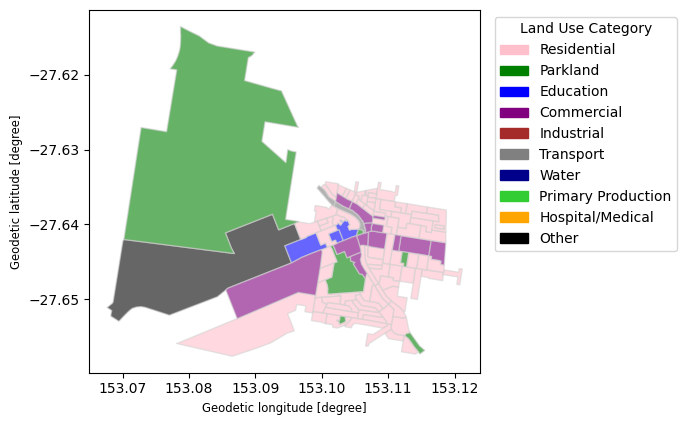

In [12]:
# Plot mesh blocks by category
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

mb_colors = {
    'Residential': 'pink',
    'Parkland': 'green',
    'Education': 'blue',
    'Commercial': 'purple',
    'Industrial': 'brown',
    'Transport': 'gray',
    'Water': 'darkblue',
    'Primary Production': 'limegreen',
    'Hospital/Medical': 'orange',
    'Other': 'black'
}

fig, ax = plt.subplots(figsize=(7, 7))

gdf_mb.plot(
    categorical=True,
    color=gdf_mb['MB_CAT21'].map(mb_colors),
    edgecolor='lightgray',
    alpha=0.6,
    ax=ax
)

# Create legend
legend_patches = [
    mpatches.Patch(color=color, label=category)
    for category, color in mb_colors.items()
]

ax.legend(
    handles=legend_patches,
    title='Land Use Category',
    loc='upper left',
    bbox_to_anchor=(1.02, 1)
)

plt.tight_layout()
plt.show()


####  Index of socio-economic disadvantage by SA1's 
• Low scores: A score below 1,000 means an area has a higher relative level of disadvantage (e.g., more low-income families or high unemployment). </br>
• High scores: A score above 1,000 means an area has a relative lack of disadvantage (it does not measure advantage, only the absence of hardship).

In [13]:
# Define function to convert arcgis.polygon to WKT geometry for a geodataframe
import geopandas as gpd
from shapely.wkt import loads

def convert_sdf_gdf(sdf, output_epsg):
    wkt_geoms=[]
    for s in sdf['SHAPE']:
       wkt_geoms.append(loads(s.WKT)) 
    # Create a geodataframe for data, and do not keep arcgis 'SHAPE' columns
    columns_to_keep = [col for col in sdf.columns if not (col.startswith("SHAPE") or col.startswith("Shape"))]
    gdf = gpd.GeoDataFrame(sdf[columns_to_keep], geometry=wkt_geoms, crs='EPSG:3857') 
    gdf = gdf.to_crs(output_epsg)
    return gdf

In [14]:
# Import ArcGIS Online module and start, i.e. 'home' tells AGO to get sigin from AGO homepage 
from arcgis.gis import GIS
gis = GIS('home')
# Get hosted feature layer using its item_id
# Title: ABS 2021 IRSD | Type: Feature Service | Owner: dpullar
item = gis.content.get("1cd47c4325114610846d125da88e7103") 
sdf_sa1 = item.layers[0].query(where=f"SA2_NAME21 = '{locationName}'").sdf 
print('Number of features: {}'.format(len(sdf_sa1)))  

gdf_sa1 = convert_sdf_gdf(sdf_sa1, 7844)
gdf_sa1.head()

Number of features: 15


,FID,SA1_CODE21,SA2_CODE21,SA2_NAME21,SA3_CODE21,SA3_NAME21,AREASQKM21,IRSD_Score,IRSD_Rank,Population,geometry
0,43044,31106133101,311061331,Logan Central,31106,Springwood - Kingston,0.1274,855.0,1,539,"POLYGON ((153.11009 -27.65066, 153.11015 -27.6..."
1,43045,31106133102,311061331,Logan Central,31106,Springwood - Kingston,0.139,663.0,1,492,"POLYGON ((153.1168 -27.63954, 153.11343 -27.63..."
2,43046,31106133103,311061331,Logan Central,31106,Springwood - Kingston,2.2271,0.0,0,0,"POLYGON ((153.07814 -27.65588, 153.07788 -27.6..."
3,43047,31106133104,311061331,Logan Central,31106,Springwood - Kingston,0.4874,646.0,1,284,"POLYGON ((153.10949 -27.64327, 153.1094 -27.64..."
4,43048,31106133105,311061331,Logan Central,31106,Springwood - Kingston,0.0986,667.0,1,415,"POLYGON ((153.11496 -27.64014, 153.11412 -27.6..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

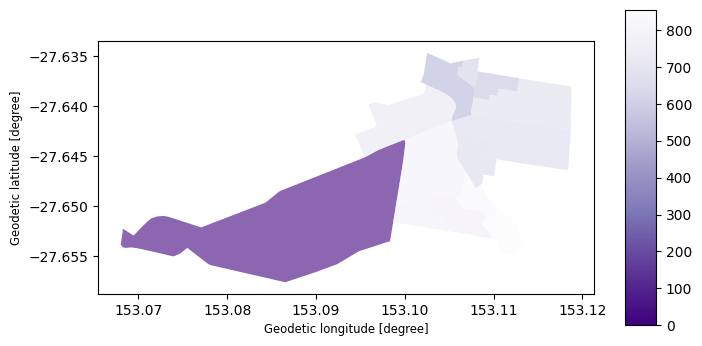

In [15]:
gdf_sa1.plot( column='IRSD_Score', cmap='Purples_r', alpha=0.6, figsize=(8, 8), legend=True)

#### Joining all tables

In [16]:
# Join the offence data for selected crime type only 
crime_type = 'Drug Offences'

# Slice to get selected crime type only
spec_crime_df = off_df[off_df.Type==crime_type]

# Join the mesh block data with the offence data
gdf_mb_spec_crime = gdf_mb.merge(spec_crime_df[['Type',	'Date',	'ABS Meshblock']], right_on='ABS Meshblock', left_on='MB_CODE21')

# Join the socio-economic score to the main dataset
gdf_mb_spec_crime = gdf_mb_spec_crime.merge(gdf_sa1[['IRSD_Score','IRSD_Rank','SA1_CODE21']], on='SA1_CODE21', how='left')


gdf_mb_spec_crime[['MB_CODE21', 'MB_CAT21', 'SA2_NAME21','Type','Date','Dwelling','Person','IRSD_Score','IRSD_Rank']]

,MB_CODE21,MB_CAT21,SA2_NAME21,Type,Date,Dwelling,Person,IRSD_Score,IRSD_Rank
0,30383381000,Residential,Logan Central,Drug Offences,2024-01-18 21:45:00,13,37,855.0,1
1,30383381000,Residential,Logan Central,Drug Offences,2024-03-09 11:00:00,13,37,855.0,1
2,30383381000,Residential,Logan Central,Drug Offences,2024-04-10 21:00:00,13,37,855.0,1
3,30383381000,Residential,Logan Central,Drug Offences,2024-04-14 21:50:13,13,37,855.0,1
4,30383381000,Residential,Logan Central,Drug Offences,2024-07-05 00:00:00,13,37,855.0,1
...,...,...,...,...,...,...,...,...,...
727,30563818900,Residential,Logan Central,Drug Offences,2024-10-03 15:15:08,0,0,511.0,1
728,30563818900,Residential,Logan Central,Drug Offences,2024-10-03 15:15:08,0,0,511.0,1
729,30563818900,Residential,Logan Central,Drug Offences,2025-06-26 13:17:35,0,0,511.0,1
730,30563818900,Residential,Logan Central,Drug Offences,2025-07-30 23:55:00,0,0,511.0,1


## Temporal Pattern

In [17]:
import pandas as pd
# transform Date column into timestamp
gdf_mb_spec_crime['Date'] = pd.to_datetime(gdf_mb_spec_crime['Date'])
gdf_mb_spec_crime['Date'].dtype

dtype('<M8[us]')

In [18]:
# Extract time components
gdf_mb_spec_crime['year'] = gdf_mb_spec_crime['Date'].dt.year
gdf_mb_spec_crime['hour'] = gdf_mb_spec_crime['Date'].dt.hour
gdf_mb_spec_crime['month'] = gdf_mb_spec_crime['Date'].dt.month
gdf_mb_spec_crime['weekday'] = gdf_mb_spec_crime['Date'].dt.dayofweek

In [19]:
# Count crimes by year and category
crime_count_table = pd.crosstab(
    gdf_mb_spec_crime['MB_CAT21'],
    gdf_mb_spec_crime['year'],
    margins=True,
    margins_name='Total'
)

# Remove the Total column, but keep the Total row
crime_count_table = crime_count_table.drop(columns='Total')

# Rename the row index label
crime_count_table.index.name = 'Land Use Category'

# Display the table
crime_count_table

year,2024,2025
Land Use Category,,
Commercial,112,118
Education,2,0
Parkland,34,30
Residential,190,163
Transport,45,38
Total,383,349


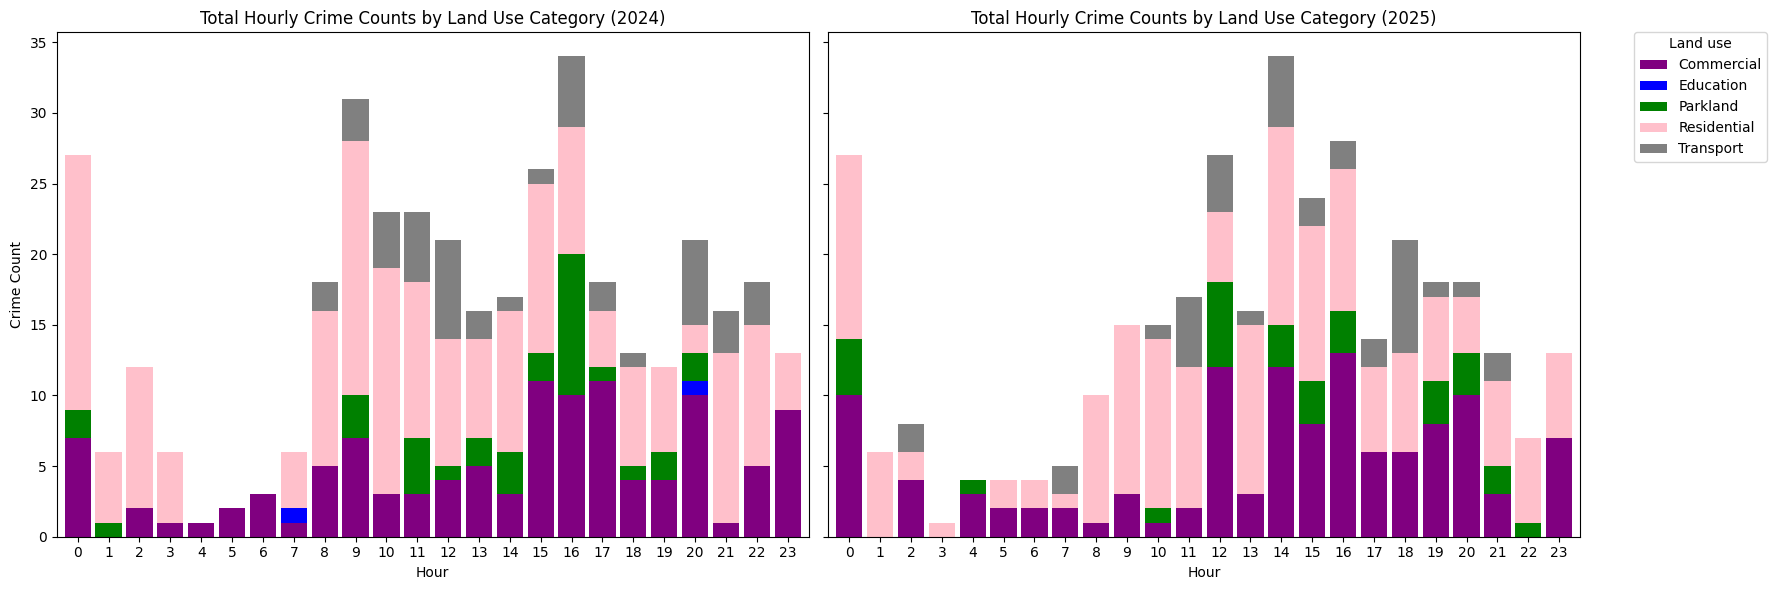

In [20]:
# Use consistent category order for both years
categories = sorted(gdf_mb_spec_crime['MB_CAT21'].dropna().unique())

# Apply consistent colors
colors = [mb_colors.get(cat, 'lightgray') for cat in categories]

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Plot for 2024 and 2025
for ax, year in zip(axes, [2024, 2025]):

    # Filter data by year
    yearly_data = gdf_mb_spec_crime[
        gdf_mb_spec_crime['year'] == year
    ]

    # Create crime counts by hour and category
    hourly_cat = pd.crosstab(
        yearly_data['hour'],
        yearly_data['MB_CAT21']
    )

    # Ensure all seven weekdays and categories are shown
    hourly_cat = hourly_cat.reindex(
        index=range(24),
        columns=categories,
        fill_value=0
    )

    # Plot stacked bar chart
    hourly_cat.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        width=0.85,
        color=colors,
        legend=False
    )

    ax.set_xlabel('Hour')
    ax.set_title(f'Total Hourly Crime Counts by Land Use Category ({year})')
    ax.set_xticks(range(24))
    ax.set_xticklabels(range(24), rotation=0)

axes[0].set_ylabel('Crime Count')

# Add a shared legend on the right
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title='Land use',
    bbox_to_anchor=(1.02, 0.95),
    loc='upper left'
)

plt.tight_layout()
plt.show()

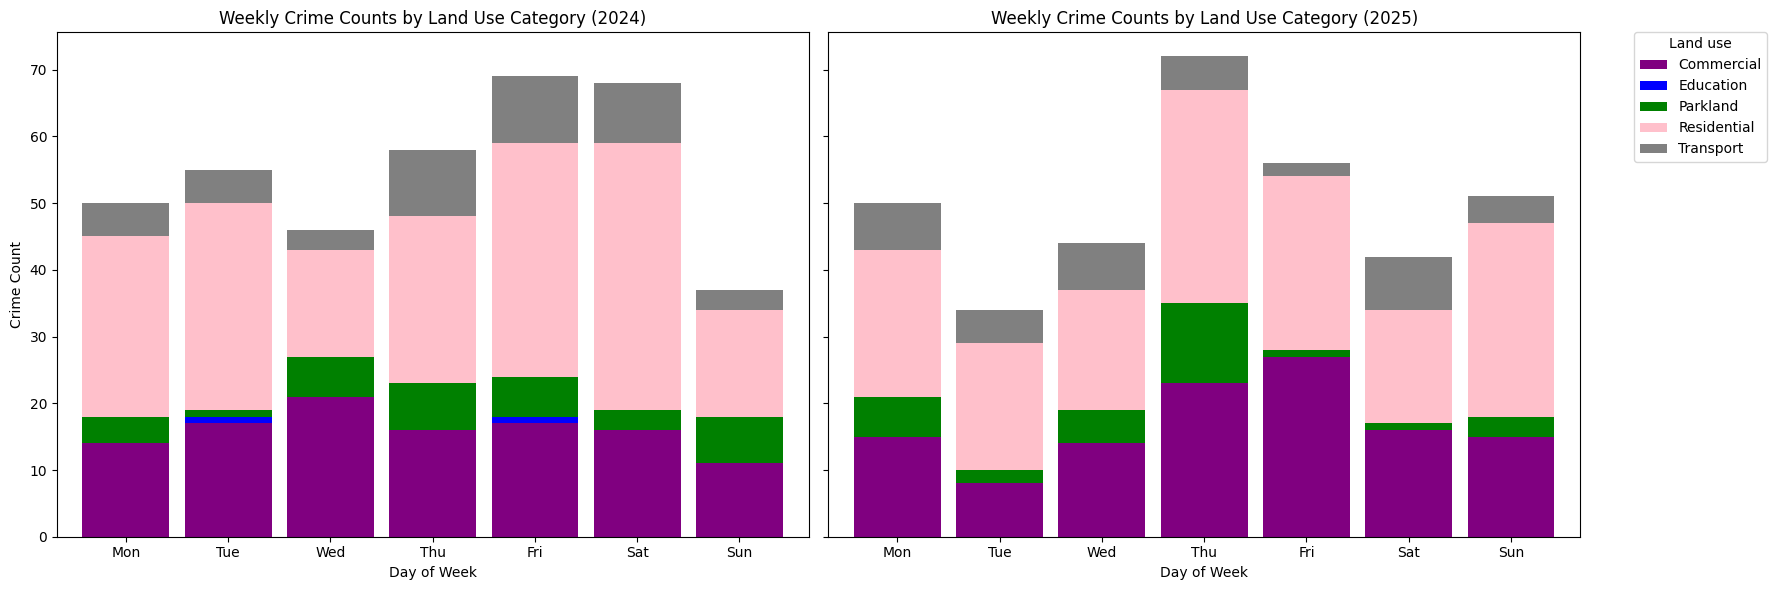

In [21]:
# Define weekday order and labels
weekday_order = range(7)
weekday_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

# Use consistent category order for both years
categories = sorted(gdf_mb_spec_crime['MB_CAT21'].dropna().unique())

# Apply consistent colors
colors = [mb_colors.get(cat, 'lightgray') for cat in categories]

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Plot for 2024 and 2025
for ax, year in zip(axes, [2024, 2025]):

    # Filter data by year
    yearly_data = gdf_mb_spec_crime[
        gdf_mb_spec_crime['year'] == year
    ]

    # Create crime counts by weekday and category
    weekday_cat = pd.crosstab(
        yearly_data['weekday'],
        yearly_data['MB_CAT21']
    )

    # Ensure all seven weekdays and categories are shown
    weekday_cat = weekday_cat.reindex(
        index=weekday_order,
        columns=categories,
        fill_value=0
    )

    # Plot stacked bar chart
    weekday_cat.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        width=0.85,
        color=colors,
        legend=False
    )

    ax.set_xlabel('Day of Week')
    ax.set_title(f'Weekly Crime Counts by Land Use Category ({year})')
    ax.set_xticks(range(7))
    ax.set_xticklabels(weekday_labels, rotation=0)

axes[0].set_ylabel('Crime Count')

# Add a shared legend on the right
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title='Land use',
    bbox_to_anchor=(1.02, 0.95),
    loc='upper left'
)

plt.tight_layout()
plt.show()

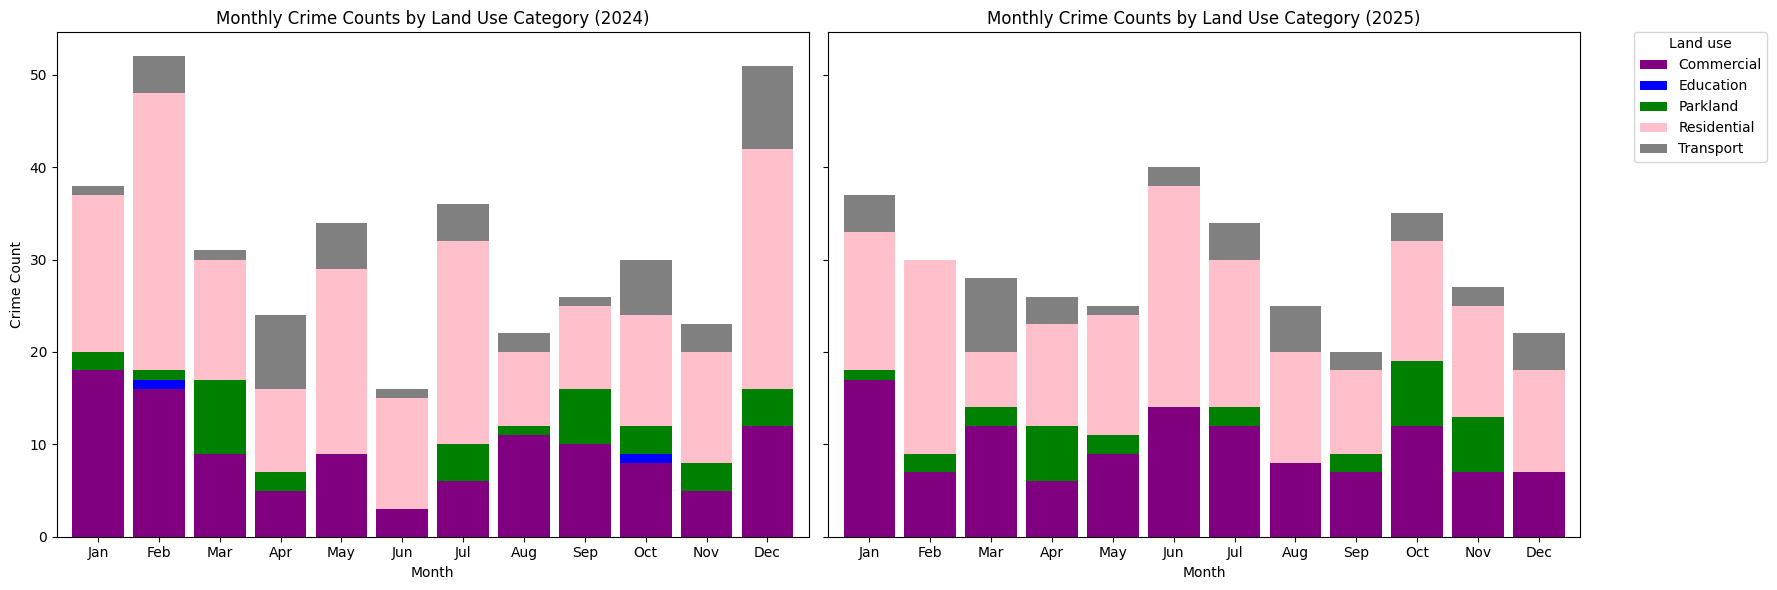

In [22]:
# Define month order and labels
month_order = range(1, 13)
month_labels = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

# Use the same category order for both years
categories = sorted(gdf_mb_spec_crime['MB_CAT21'].dropna().unique())

# Apply consistent colors
colors = [mb_colors.get(cat, 'lightgray') for cat in categories]

# Create two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Plot for 2024 and 2025
for ax, year in zip(axes, [2024, 2025]):

    # Filter data by year
    yearly_data = gdf_mb_spec_crime[
        gdf_mb_spec_crime['year'] == year
    ]

    # Create monthly crime counts by category
    monthly_cat = pd.crosstab(
        yearly_data['month'],
        yearly_data['MB_CAT21']
    )

    # Ensure all 12 months and categories are shown
    monthly_cat = monthly_cat.reindex(
        index=month_order,
        columns=categories,
        fill_value=0
    )

    # Plot stacked bar chart
    monthly_cat.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        width=0.85,
        color=colors,
        legend=False
    )

    ax.set_xlabel('Month')
    ax.set_title(f'Monthly Crime Counts by Land Use Category ({year})')
    ax.set_xticks(range(12))
    ax.set_xticklabels(month_labels, rotation=0)

axes[0].set_ylabel('Crime Count')

# Add a shared legend on the right
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title='Land use',
    bbox_to_anchor=(1.02, 0.95),
    loc='upper left'
)

plt.tight_layout()
plt.show()

## Spatial pattern

### Count by land use

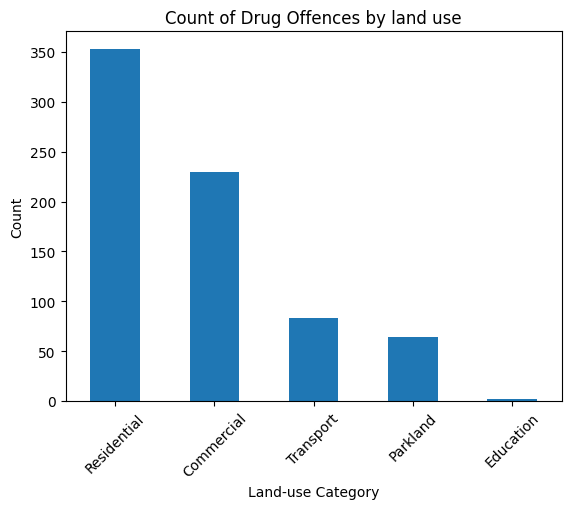

In [23]:
gdf_mb_spec_crime['MB_CAT21'].value_counts().plot(kind='bar')

plt.xlabel('Land-use Category')
plt.ylabel('Count')
plt.title(f'Count of {crime_type} by land use')
plt.xticks(rotation=45)
plt.show()

### Crime Count per area by landuse

In [24]:
crime_counts_by_lu = gdf_mb_spec_crime.to_crs('EPSG:7856')

crime_counts_by_lu['area_m2'] = crime_counts_by_lu.geometry.area

crime_counts_by_lu = (
    crime_counts_by_lu
    .groupby('MB_CAT21')
    .agg({'Type': 'count', 'area_m2': 'sum'})
    .rename(columns={'Type': 'Crime_Count'})
    .reset_index()
)

# Filter out rows with zero crime counts
crime_counts_by_lu = crime_counts_by_lu[
    crime_counts_by_lu['Crime_Count'] > 0
].copy()

# Calculate crime count per km²
crime_counts_by_lu['Crime Count per km2'] = (
    crime_counts_by_lu['Crime_Count']
    / crime_counts_by_lu['area_m2']
    * 1_000_000
)

crime_counts_by_lu

,MB_CAT21,Crime_Count,area_m2,Crime Count per km2
0,Commercial,230,1.230572e+07,18.690492
1,Education,2,2.679742e+05,7.463406
2,Parkland,64,1.490094e+07,4.295032
3,Residential,353,1.043928e+07,33.814603
4,Transport,83,3.479326e+06,23.855198


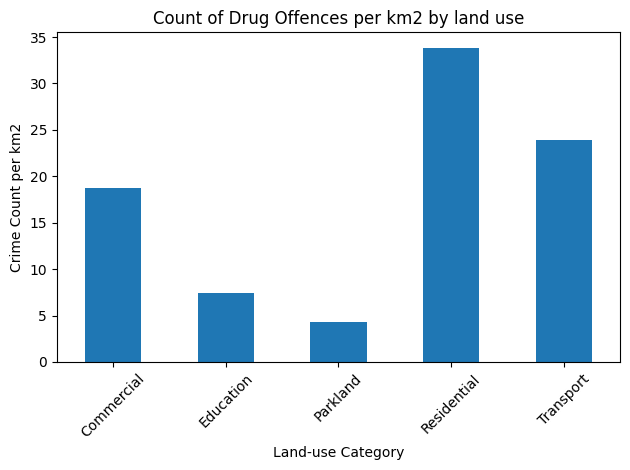

In [25]:
crime_counts_by_lu.plot(
    x='MB_CAT21',
    y='Crime Count per km2',
    kind='bar',
    legend=False
)

plt.xlabel('Land-use Category')
plt.ylabel('Crime Count per km2')
plt.xticks(rotation=45)
plt.title(f'Count of {crime_type} per km2 by land use')
plt.tight_layout()
plt.show()

### Summarize by meshblock

In [26]:
crime_counts_by_lu = gdf_mb_spec_crime.copy()

# Count crimes and unique meshblocks in each land-use category
crime_counts_by_lu = (
    crime_counts_by_lu
    .groupby('MB_CAT21')
    .agg(
        Crime_Count=('Type', 'count'),
        Meshblock_Count=('MB_CODE21', 'nunique')
    )
    .reset_index()
)

# Filter out rows with zero crime counts
crime_counts_by_lu = crime_counts_by_lu[
    crime_counts_by_lu['Crime_Count'] > 0
].copy()

# Calculate crime count per meshblock
crime_counts_by_lu['Crime Count per Meshblock'] = (
    crime_counts_by_lu['Crime_Count']
    / crime_counts_by_lu['Meshblock_Count']
)

crime_counts_by_lu

,MB_CAT21,Crime_Count,Meshblock_Count,Crime Count per Meshblock
0,Commercial,230,11,20.909091
1,Education,2,1,2.000000
2,Parkland,64,2,32.000000
3,Residential,353,54,6.537037
4,Transport,83,1,83.000000


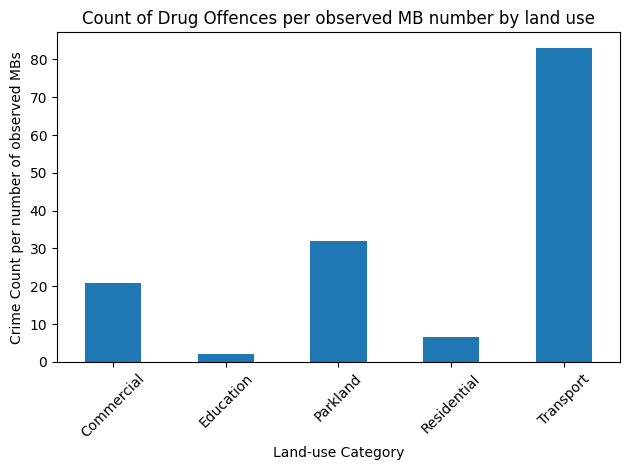

In [27]:
crime_counts_by_lu.plot(
    x='MB_CAT21',
    y='Crime Count per Meshblock',
    kind='bar',
    legend=False
)

plt.xlabel('Land-use Category')
plt.ylabel('Crime Count per number of observed MBs')
plt.xticks(rotation=45)
plt.title(f'Count of {crime_type} per observed MB number by land use')
plt.tight_layout()
plt.show()

In [28]:
# Summarise the offences by mesh block
crime_counts = gdf_mb_spec_crime.groupby(['MB_CODE21','MB_CAT21','Dwelling','Person','geometry','IRSD_Score','IRSD_Rank']).agg({'Type':'count'}).rename(columns={'Type': 'Crime_Count'})
crime_counts.reset_index(inplace=True)

# Convert back to a GeoDataFrame
crime_counts = geopandas.GeoDataFrame(
    crime_counts,
    geometry='geometry',
    crs=gdf_mb.crs
)

Text(0.5, 1.0, 'Drug Offences count in Logan Central, \n Highlighting top 5 Meshblock')

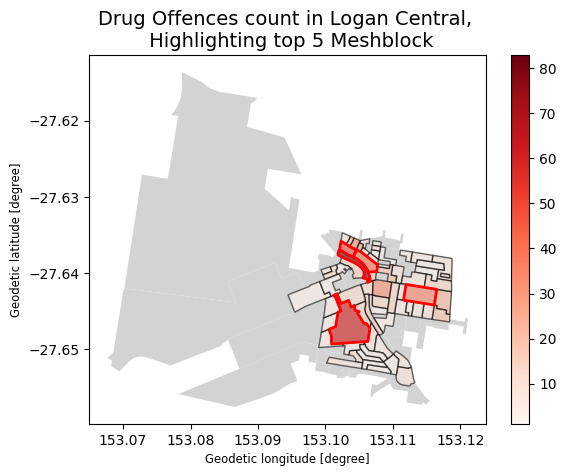

In [29]:
# Plot all meshblocks in light gray
ax = gdf_mb.plot(color='lightgray')

# Plot crime counts using the original format
crime_counts.plot(
    column='Crime_Count',
    cmap='Reds',
    alpha=0.6,
    legend=True,
    figsize=(5, 5),
    edgecolor='black',
    ax=ax
)

# Highlight the top five meshblocks with red borders
top5 = crime_counts.nlargest(5, 'Crime_Count')

top5.boundary.plot(
    ax=ax,
    color='red',
    linewidth=2
)

# Title
ax.set_title(
    f'{crime_type} count in {locationName}, \n Highlighting top 5 Meshblock',
    fontsize=14
)

In [30]:
crime_counts.sort_values(by='Crime_Count', ascending=False)

,MB_CODE21,MB_CAT21,Dwelling,Person,geometry,IRSD_Score,IRSD_Rank,Crime_Count
10,30395430000,Transport,0,0,"POLYGON ((153.10412 -27.63791, 153.10466 -27.6...",511.0,1,83
26,30397000000,Parkland,0,0,"POLYGON ((153.10261 -27.64921, 153.10254 -27.6...",777.0,1,61
60,30563018500,Commercial,12,40,"POLYGON ((153.10305 -27.6362, 153.10358 -27.63...",511.0,1,47
56,30397431000,Commercial,11,17,"POLYGON ((153.10773 -27.63891, 153.1077 -27.63...",511.0,1,39
7,30395340000,Commercial,6,0,"POLYGON ((153.11158 -27.64357, 153.11192 -27.6...",646.0,1,34
...,...,...,...,...,...,...,...,...
33,30397110000,Residential,29,66,"POLYGON ((153.10176 -27.64019, 153.10154 -27.6...",707.0,1,1
48,30397310000,Residential,42,112,"POLYGON ((153.11009 -27.65066, 153.11088 -27.6...",855.0,1,1
42,30397252000,Residential,33,101,"POLYGON ((153.10972 -27.65322, 153.10686 -27.6...",758.0,1,1
36,30397180000,Residential,45,135,"POLYGON ((153.09974 -27.64588, 153.09978 -27.6...",777.0,1,1


### Correlation

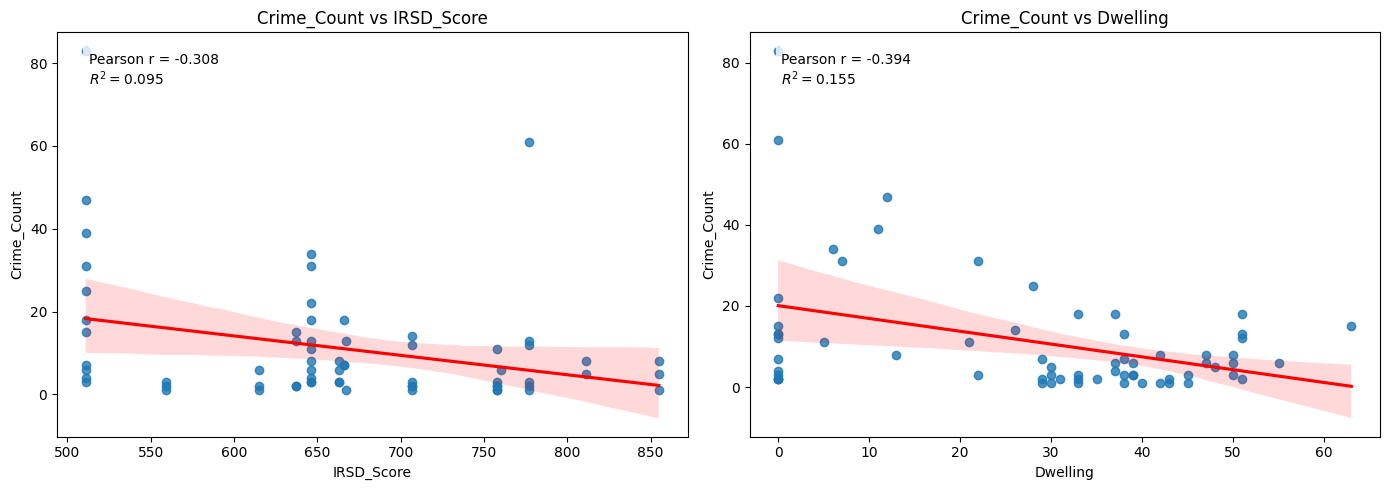

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

# Define variables
explanatory_vars = ['IRSD_Score', 'Dwelling']
response_var = 'Crime_Count'

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, explanatory_var in zip(axes, explanatory_vars):

    # Remove missing values
    data = crime_counts[[response_var, explanatory_var]].dropna()

    x = data[explanatory_var]
    y = data[response_var]

    # Linear regression
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    r2 = r_value**2

    # Plot regression line and scatter points
    sns.regplot(
        data=data,
        x=explanatory_var,
        y=response_var,
        ax=ax,
        line_kws={'color': 'red'}
    )

    # Display correlation coefficient and R-squared
    ax.text(
        0.05, 0.95,
        f'Pearson r = {r_value:.3f}\n$R^2 = {r2:.3f}$',
        transform=ax.transAxes,
        verticalalignment='top',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none')
    )

    # Labels and title
    ax.set_xlabel(explanatory_var)
    ax.set_ylabel(response_var)
    ax.set_title(f'{response_var} vs {explanatory_var}')

plt.tight_layout()
plt.show()

## Overlay on openstreet map

In [32]:
# Uncomment to install folium
# !pip install folium

In [33]:
import folium

# Folium requires geographic coordinates (latitude/longitude)
crime_counts_map = crime_counts.to_crs(epsg=4326)
center = [
    crime_counts_map.geometry.union_all().centroid.y,
    crime_counts_map.geometry.union_all().centroid.x
]
m = folium.Map(
    location=center,
    zoom_start=15,
    tiles='OpenStreetMap'
)

# Add choropleth layer
folium.Choropleth(
    geo_data=crime_counts_map,
    data=crime_counts_map,
    columns=['MB_CODE21', 'Crime_Count'],
    key_on='feature.properties.MB_CODE21',
    fill_color='Reds',
    fill_opacity=0.5,
    line_color='black',
    line_weight=1,
    legend_name='Crime Count'
).add_to(m)

# Highlight the top five meshblocks with red borders
top2 = crime_counts.nlargest(2, 'Crime_Count')

top2.boundary.plot(
    ax=ax,
    color='red',
    linewidth=2
)

# Add the top five meshblocks with red borders
folium.GeoJson(
    top2,
    name="Top 2 Crime Meshblocks",
    style_function=lambda feature: {
        'color': 'red',
        'weight': 5,
        'fillColor': 'red',
        'fillOpacity': 0.1
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['Crime_Count'],
        aliases=['Crime Count:']
    )
).add_to(m)


m

## Distance Decay Relationship with top 2 crime MB

In [34]:
# Set target MB
target_MB_1 = '30395430000'  # Woodridge Train Station
target_MB_2 = '30397000000'  # Logan Gardens Park

# Get ABS meshblocks that not the target MB
gdf_rest = crime_counts.query(f"MB_CODE21!='{target_MB_1}'& MB_CODE21!='{target_MB_2}'")
gdf_rest = gdf_rest.to_crs('EPSG:7856')
# Get the ABS meshblocks for target MB (center of crime) 
gdf_Train_Station = crime_counts.query("MB_CODE21=='{}'".format(target_MB_1))
gdf_Park = crime_counts.query("MB_CODE21=='{}'".format(target_MB_2))
gdf_Train_Station = gdf_Train_Station.to_crs('EPSG:7856')
gdf_Park = gdf_Park.to_crs('EPSG:7856')

# using gpd.sjoin_nearest to join two gdf and calculate the nearest distance
gdf_target_mb_joined = gpd.sjoin_nearest(gdf_rest,gdf_Train_Station[['geometry']], how = "left", distance_col = 'dist_decay_Train_Station')
gdf_target_mb_joined_2 = gpd.sjoin_nearest(gdf_rest,gdf_Park[['geometry']], how = "left", distance_col = 'dist_decay_Park')

gdf_target_mb_joined.head(10)

,MB_CODE21,MB_CAT21,Dwelling,Person,geometry,IRSD_Score,IRSD_Rank,Crime_Count,index_right,dist_decay_Train_Station
0,30383381000,Residential,13,37,"POLYGON ((510898.631 6941191.821, 510903.378 6...",855.0,1,8,10,1299.694944
1,30383680000,Residential,43,138,"POLYGON ((510852.332 6941894.637, 510747.945 6...",637.0,1,2,10,513.757473
2,30395140000,Residential,21,70,"POLYGON ((510320.732 6941549.784, 510324.647 6...",758.0,1,11,10,997.083669
3,30395160000,Residential,31,108,"POLYGON ((510380.011 6941567.447, 510459.258 6...",758.0,1,2,10,971.825143
4,30395220000,Residential,40,128,"POLYGON ((511173.9 6942684.53, 511189.573 6942...",667.0,1,1,10,662.664282
5,30395230000,Residential,50,138,"POLYGON ((511521.68 6942721.639, 511189.573 69...",663.0,1,3,10,695.694567
6,30395240000,Residential,50,65,"POLYGON ((511683.351 6942598.435, 511676.153 6...",663.0,1,8,10,1028.793807
7,30395340000,Commercial,6,0,"POLYGON ((511006.904 6942275.712, 511040.833 6...",646.0,1,34,10,527.817034
8,30395350000,Commercial,0,0,"POLYGON ((511707.321 6942404.331, 511707.145 6...",646.0,1,22,10,982.459612
9,30395360000,Residential,50,160,"POLYGON ((511715.667 6942883.625, 511717.009 6...",663.0,1,6,10,935.231705


In [35]:
gdf_target_mb_joined_2.head(10)

,MB_CODE21,MB_CAT21,Dwelling,Person,geometry,IRSD_Score,IRSD_Rank,Crime_Count,index_right,dist_decay_Park
0,30383381000,Residential,13,37,"POLYGON ((510898.631 6941191.821, 510903.378 6...",855.0,1,8,26,569.278803
1,30383680000,Residential,43,138,"POLYGON ((510852.332 6941894.637, 510747.945 6...",637.0,1,2,26,126.226473
2,30395140000,Residential,21,70,"POLYGON ((510320.732 6941549.784, 510324.647 6...",758.0,1,11,26,115.267684
3,30395160000,Residential,31,108,"POLYGON ((510380.011 6941567.447, 510459.258 6...",758.0,1,2,26,101.791531
4,30395220000,Residential,40,128,"POLYGON ((511173.9 6942684.53, 511189.573 6942...",667.0,1,1,26,997.424386
5,30395230000,Residential,50,138,"POLYGON ((511521.68 6942721.639, 511189.573 69...",663.0,1,3,26,1064.177660
6,30395240000,Residential,50,65,"POLYGON ((511683.351 6942598.435, 511676.153 6...",663.0,1,8,26,1275.477933
7,30395340000,Commercial,6,0,"POLYGON ((511006.904 6942275.712, 511040.833 6...",646.0,1,34,26,636.997412
8,30395350000,Commercial,0,0,"POLYGON ((511707.321 6942404.331, 511707.145 6...",646.0,1,22,26,998.335789
9,30395360000,Residential,50,160,"POLYGON ((511715.667 6942883.625, 511717.009 6...",663.0,1,6,26,1219.371347


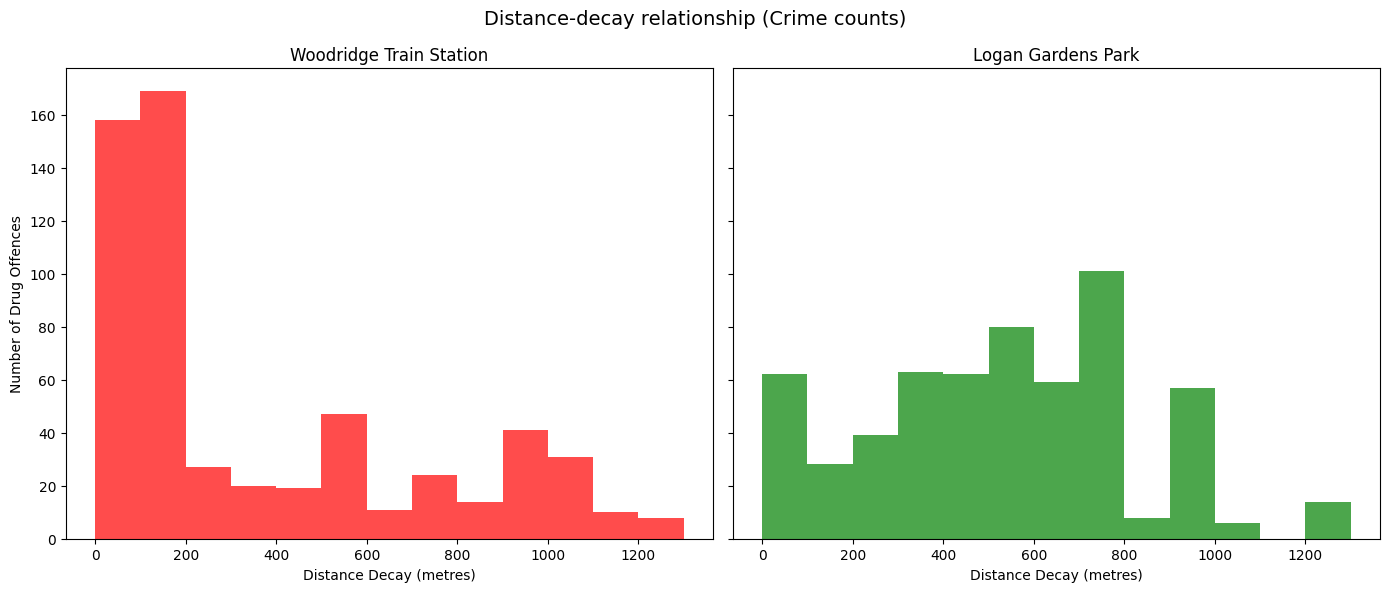

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# Distance data
dist_train = gdf_target_mb_joined['dist_decay_Train_Station'].dropna()
dist_park = gdf_target_mb_joined_2['dist_decay_Park'].dropna()

# Set the same bin width for both histograms (in metres)
bin_width = 100

# Create shared bin edges covering both datasets
max_distance = max(dist_train.max(), dist_park.max())
bins = np.arange(0, max_distance + bin_width, bin_width)

# Create two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Subplot 1: Woodridge Train Station
axes[0].hist(
    dist_train,
    bins=bins,
    alpha=0.7,
    color="red",
    weights=gdf_target_mb_joined.loc[dist_train.index, "Crime_Count"]
)

axes[0].set_xlabel("Distance Decay (metres)")
axes[0].set_ylabel("Number of Drug Offences")
axes[0].set_title("Woodridge Train Station")

# Subplot 2: Logan Gardens Park
axes[1].hist(
    dist_park,
    bins=bins,
    alpha=0.7,
    color="green",
    weights=gdf_target_mb_joined_2.loc[dist_park.index, "Crime_Count"]
)

axes[1].set_xlabel("Distance Decay (metres)")
axes[1].set_title("Logan Gardens Park")

# Overall title
fig.suptitle(
    "Distance-decay relationship (Crime counts)",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [37]:
! jupyter nbconvert --to html f3fac154315b41cfac15128b47b9abca.ipynb

/opt/conda/bin/jupyter-nbconvert:6: DeprecationWarning: Parsing dates involving a day of month without a year specified is ambiguious
and fails to parse leap day. The default behavior will change in Python 3.15
to either always raise an exception or to use a different default year (TBD).
To avoid trouble, add a specific year to the input & format.
See https://github.com/python/cpython/issues/70647.
  from nbconvert.nbconvertapp import main
[NbConvertApp] Converting notebook f3fac154315b41cfac15128b47b9abca.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 12 image(s).
[NbConvertApp] Writing 1238828 bytes to f3fac154315b41cfac15128b47b9abca.html
